# C3 — Conception évolutionnaire de molécules candidates

Analyses et visualisations du projet. **Ce notebook est autonome** : il
installe ses dépendances, exécute les expériences et produit toutes les
figures du rapport. Aucun fichier de résultats préalable n'est nécessaire.

| Membre | Figures |
|---|---|
| [@guilhermelopo](https://github.com/guilhermelopo) | 1 (validité), 2 (médicaments connus), 5 (diversité) |
| [@lucaslapenda-cpu](https://github.com/lucaslapenda-cpu) | 3 (convergence), 4 (Pareto), 6 (meilleures molécules) |

## Comment l'exécuter

**Google Colab** — téléverser le dossier `groupe-molevo` puis exécuter
« Exécuter tout ». La première cellule installe RDKit et selfies.

**En local** — depuis `groupe-molevo/` :
`pip install -r requirements.txt && jupyter lab notebooks/analise.ipynb`

> Durée totale avec les paramètres par défaut : environ 3 à 6 minutes.
> Les paramètres sont tous dans la cellule « Paramètres » ci-dessous :
> un seul endroit à modifier pour refaire toutes les mesures.

In [1]:
# Dependances. Sans effet si elles sont deja installees.
# `import importlib.util` et non `import importlib` : le sous-module util
# n'est pas charge automatiquement par le paquet parent.
import importlib.util
import subprocess, sys

for paquet, module in [("rdkit", "rdkit"), ("selfies", "selfies"),
                       ("matplotlib", "matplotlib"), ("pandas", "pandas")]:
    if importlib.util.find_spec(module) is None:
        print(f"installation de {paquet}...")
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", paquet], check=True)

import rdkit, selfies
print(f"rdkit {rdkit.__version__} | selfies {selfies.__version__}")

rdkit 2026.09.2 | selfies 2.1.1


In [2]:
# Localise le dossier du projet, pour que `src` soit importable.
#
# Dans Colab, le notebook arrive SEUL : sans le reste du dossier, cette
# cellule echoue et toutes les suivantes echouent en cascade. Elle cherche
# donc le dossier partout ou il peut etre, puis dezippe une archive
# groupe-molevo.zip deja presente, et n'ouvre une boite de televersement
# qu'en dernier recours.
import sys, zipfile
from pathlib import Path

REPERE = Path("src") / "representation.py"


def trouver_racine():
    bases = [Path.cwd(), Path.cwd().parent, Path("/content")]
    for base in bases:
        for candidat in [base, base / "groupe-molevo"]:
            try:
                if (candidat / REPERE).exists():
                    return candidat.resolve()
            except OSError:
                continue
    # Recherche en profondeur, bornee au repertoire courant.
    try:
        for p in Path.cwd().rglob("representation.py"):
            if p.parent.name == "src":
                return p.parent.parent.resolve()
    except OSError:
        pass
    return None


def dezipper_si_present():
    """Cherche groupe-molevo.zip la ou il arrive d'habitude et l'extrait."""
    for dossier in [Path.cwd(), Path("/content"), Path.cwd().parent]:
        try:
            archives = list(dossier.glob("groupe-molevo*.zip"))
        except OSError:
            continue
        for a in archives:
            with zipfile.ZipFile(a) as z:
                z.extractall(dossier)
            print(f"  {a.name} decompresse dans {dossier}")
            return True
    return False


racine = trouver_racine()

if racine is None and dezipper_si_present():
    racine = trouver_racine()

if racine is None and ("google.colab" in sys.modules or Path("/content").exists()):
    print("Dossier du projet introuvable. Selectionnez groupe-molevo.zip :")
    try:
        from google.colab import files
        envoyes = files.upload()
        for nom in envoyes:
            if nom.endswith(".zip"):
                with zipfile.ZipFile(nom) as z:
                    z.extractall(".")
        racine = trouver_racine()
    except Exception as e:
        print(f"  (televersement indisponible : {e})")

if racine is None:
    barre = "=" * 68
    message = "\n".join([
        "",
        barre,
        "ARRET : le dossier du projet n'a pas ete trouve.",
        barre,
        "",
        "Ce notebook a besoin du dossier groupe-molevo (src/, tests/...).",
        "Seul, il ne peut rien faire : les cellules suivantes echoueront",
        "toutes, et leurs erreurs ne seront que des consequences de celle-ci.",
        "",
        "Dans Colab, au choix :",
        "",
        "  A) Panneau Fichiers (icone dossier a gauche) -> Televerser ->",
        "     groupe-molevo.zip, puis reexecuter CETTE cellule.",
        "",
        "  B) Dans une cellule :",
        "       !git clone -b c3-evolucao-moleculas <url-du-fork> /content/d",
        "       %cd /content/d",
        "     puis reexecuter cette cellule.",
        "",
        "En local : ouvrez le notebook depuis groupe-molevo/ ou notebooks/.",
        "",
    ])
    raise SystemExit(message)

sys.path.insert(0, str(racine))
(racine / "notebooks").mkdir(parents=True, exist_ok=True)
print(f"racine du projet : {racine}")

racine du projet : /content/c3/groupe-molevo


### Autotest

Avant de lancer quoi que ce soit de long, on importe les neuf modules et on
vérifie qu'ils répondent. **Si cette cellule échoue, le problème est ici et
nulle part ailleurs** — inutile de lire les erreurs des cellules suivantes,
elles ne seraient que des conséquences.

In [3]:
# Autotest : localise une panne au lieu de la laisser se propager.
echecs = []

def essayer(nom, fn):
    try:
        resultat = fn()
        print(f"  ok    {nom}  ->  {resultat}")
    except Exception as e:
        echecs.append((nom, f"{type(e).__name__}: {e}"))
        print(f"  ECHEC {nom}  ->  {type(e).__name__}: {e}")

print("imports et appels de base\n")

essayer("import src.representation", lambda: __import__("src.representation", fromlist=["x"]).__name__)
essayer("import src.objectives", lambda: __import__("src.objectives", fromlist=["x"]).__name__)
essayer("import src.operators", lambda: __import__("src.operators", fromlist=["x"]).__name__)
essayer("import src.ga", lambda: __import__("src.ga", fromlist=["x"]).__name__)
essayer("import src.baselines", lambda: __import__("src.baselines", fromlist=["x"]).__name__)
essayer("import src.diversity", lambda: __import__("src.diversity", fromlist=["x"]).__name__)
essayer("import src.pareto", lambda: __import__("src.pareto", fromlist=["x"]).__name__)
essayer("import src.verifier", lambda: __import__("src.verifier", fromlist=["x"]).__name__)

from src import representation as _rep
essayer("SMILES -> SELFIES", lambda: _rep.de_smiles("CCO"))
essayer("SELFIES -> SMILES", lambda: _rep.para_smiles(_rep.de_smiles("CCO")))
essayer("taille de l'alphabet", lambda: len(_rep.alfabeto()))

from src import objectives as _obj
essayer("QED + SA (sascorer)", lambda: _obj.notas(_rep.de_smiles("CCO")))

# Cas degenere : une chaine SELFIES peut se decoder en SMILES VIDE, et
# Chem.MolFromSmiles("") renvoie une molecule sans atome -- pas None.
# Elle traversait le test `is None` et faisait renvoyer None au sascorer,
# d'ou un TypeError au milieu de la troisieme generation.
essayer("chaine degeneree [Ring1]", lambda: _obj.notas("[Ring1]").valida)
essayer("aptitude d'une degeneree", lambda: _obj.aptidao("[Ring1]"))

if echecs:
    print("\n" + "=" * 68)
    print(f"{len(echecs)} echec(s). Corrigez-les avant de continuer :")
    for nom, msg in echecs:
        print(f"  - {nom} : {msg}")
    print("=" * 68)
    raise SystemExit("autotest en echec -- voir ci-dessus")

print("\nautotest complet : les neuf modules repondent.")

imports et appels de base

  ok    import src.representation  ->  src.representation
  ok    import src.objectives  ->  src.objectives
  ok    import src.operators  ->  src.operators
  ok    import src.ga  ->  src.ga
  ok    import src.baselines  ->  src.baselines
  ok    import src.diversity  ->  src.diversity
  ok    import src.pareto  ->  src.pareto
  ok    import src.verifier  ->  src.verifier
  ok    SMILES -> SELFIES  ->  [C][C][O]
  ok    SELFIES -> SMILES  ->  CCO
  ok    taille de l'alphabet  ->  69


  ok    QED + SA (sascorer)  ->  Notas(qed=0.4068079656553945, sa=1.9802570386349831, sa_norm=0.8910825512627797, valida=True)
  ok    chaine degeneree [Ring1]  ->  False
  ok    aptitude d'une degeneree  ->  0.0

autotest complet : les neuf modules repondent.


In [4]:
import matplotlib.pyplot as plt
import matplotlib as mpl

# Style sobre et lisible en projection. Pas de couleur decorative :
# chaque couleur porte une information.
mpl.rcParams.update({
    "figure.dpi": 110,
    "figure.figsize": (7.5, 4.2),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "grid.linestyle": "-",
    "font.size": 11,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "legend.frameon": False,
})

BLEU, ROUGE, VERT, GRIS = "#2a56c6", "#b5362a", "#0c6f63", "#8893a3"

## Paramètres

Un seul endroit à modifier. Les graines sont fixées : réexécuter le notebook
donne exactement les mêmes nombres, ce qui est la condition de
reproductibilité exigée par le guide.

In [5]:
GRAINES   = 5        # nombre de graines aleatoires (>= 5 pour le rapport)
POP       = 60       # taille de la population
GENERATIONS = 60     # nombre de generations
PESO_QED  = 0.5      # poids du QED dans la somme ponderee (1.0 = plan B)
N_MUTACOES = 2000    # mutations par representation, test de validite
GRAINE_VALIDITE = 12345

BUDGET = POP * GENERATIONS   # evaluations par methode et par graine
print(f"budget : {BUDGET} evaluations par methode et par graine")
print(f"total  : {BUDGET * 3 * GRAINES} evaluations sur l'ensemble du notebook")

budget : 3600 evaluations par methode et par graine
total  : 54000 evaluations sur l'ensemble du notebook


## Figure 1 — Validité sous mutation : la justification du projet

C'est la mesure qui justifie tout le reste. On applique la **même
perturbation conceptuelle** aux deux représentations — une altération d'une
unité (un caractère du SMILES, un jeton du SELFIES) — et on compte combien
de fois le résultat est encore une molécule que RDKit sait lire.

Si cet écart n'était pas large, il n'y aurait aucune raison d'utiliser
SELFIES.

In [6]:
import random
from rdkit import Chem, RDLogger
import selfies as sf

RDLogger.DisableLog("rdApp.*")

MEDICAMENTS = {
    "aspirine":      "CC(=O)Oc1ccccc1C(=O)O",
    "paracetamol":   "CC(=O)Nc1ccc(O)cc1",
    "ibuprofene":    "CC(C)Cc1ccc(cc1)C(C)C(=O)O",
    "cafeine":       "Cn1cnc2c1c(=O)n(C)c(=O)n2C",
    "penicilline G": "CC1(C)SC2C(NC(=O)Cc3ccccc3)C(=O)N2C1C(=O)O",
    "atorvastatine": "CC(C)c1c(C(=O)Nc2ccccc2)c(-c2ccccc2)c(-c2ccc(F)cc2)n1CCC(O)CC(O)CC(=O)O",
}

rng = random.Random(GRAINE_VALIDITE)
alphabet_selfies = sorted(sf.get_semantic_robust_alphabet())
alphabet_smiles = list("CNOSFPcnos()[]=#123456+-")

# On pre-encode une fois : sf.encoder peut refuser un SMILES (chimie hors
# du domaine de la bibliotheque), et on veut le savoir ici plutot qu'au
# milieu de la boucle.
departs = []
refuses = []
for nom, smi in MEDICAMENTS.items():
    try:
        departs.append((smi, list(sf.split_selfies(sf.encoder(smi)))))
    except Exception as e:
        refuses.append((nom, f"{type(e).__name__}: {e}"))

if refuses:
    print("SMILES refuses par sf.encoder (exclus de la mesure) :")
    for nom, msg in refuses:
        print(f"  {nom} -- {msg}")
    print()
if not departs:
    raise SystemExit("aucun SMILES de depart utilisable : verifiez MEDICAMENTS")

valides_smiles = valides_selfies = 0
casses = []

for i in range(N_MUTACOES):
    base, jetons_base = departs[i % len(departs)]

    # SMILES : remplacer un caractere
    p = rng.randrange(len(base))
    mute = base[:p] + rng.choice(alphabet_smiles) + base[p + 1:]
    if Chem.MolFromSmiles(mute) is not None:
        valides_smiles += 1
    elif len(casses) < 6:
        casses.append((base, mute))

    # SELFIES : remplacer un jeton
    jetons = list(jetons_base)
    p = rng.randrange(len(jetons))
    jetons[p] = rng.choice(alphabet_selfies)
    if Chem.MolFromSmiles(sf.decoder("".join(jetons))) is not None:
        valides_selfies += 1

pct_smiles = 100 * valides_smiles / N_MUTACOES
pct_selfies = 100 * valides_selfies / N_MUTACOES

print(f"{N_MUTACOES} mutations d'une unite par representation\n")
print(f"  SMILES  : {pct_smiles:5.1f} %  ({valides_smiles} molecules valides)")
print(f"  SELFIES : {pct_selfies:5.1f} %  ({valides_selfies} molecules valides)")
print(f"\n  facteur : x{pct_selfies / max(pct_smiles, 0.05):.1f}")
print("\nExemples de SMILES casses par une seule substitution :")
for avant, apres in casses[:4]:
    print(f"  {avant}\n  -> {apres}\n")

2000 mutations d'une unite par representation

  SMILES  :  13.7 %  (274 molecules valides)
  SELFIES : 100.0 %  (2000 molecules valides)

  facteur : x7.3

Exemples de SMILES casses par une seule substitution :
  CC(=O)Oc1ccccc1C(=O)O
  -> CC(=O)Oc1cccc-1C(=O)O

  CC(C)Cc1ccc(cc1)C(C)C(=O)O
  -> CC(C))c1ccc(cc1)C(C)C(=O)O

  Cn1cnc2c1c(=O)n(C)c(=O)n2C
  -> Cn1cnc2c2c(=O)n(C)c(=O)n2C

  CC1(C)SC2C(NC(=O)Cc3ccccc3)C(=O)N2C1C(=O)O
  -> CC1(C)SC2C(NC(=O)Cc3ccccc3)C(=O)N2C1C(=2)O



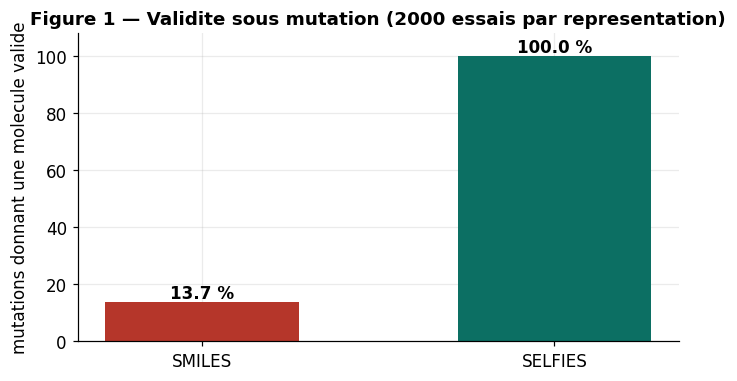

In [7]:
fig, ax = plt.subplots(figsize=(6.4, 3.6))
barres = ax.bar(["SMILES", "SELFIES"], [pct_smiles, pct_selfies],
                color=[ROUGE, VERT], width=0.55)
for barre, valeur in zip(barres, [pct_smiles, pct_selfies]):
    ax.text(barre.get_x() + barre.get_width() / 2, valeur + 1.5,
            f"{valeur:.1f} %", ha="center", fontweight="bold")

ax.set_ylabel("mutations donnant une molecule valide")
ax.set_ylim(0, 108)
ax.set_title(f"Figure 1 — Validite sous mutation ({N_MUTACOES} essais par representation)")
ax.set_axisbelow(True)
plt.tight_layout()
plt.savefig(racine / "notebooks" / "fig1_validite.png", dpi=150, bbox_inches="tight")
plt.show()

**À interpréter dans le rapport.** La validité de SELFIES n'est pas une
performance de l'algorithme : c'est une propriété de la grammaire, obtenue
par construction. Le chiffre de SMILES, lui, dépend de l'alphabet de
substitution choisi — précisez le vôtre, il est dans la cellule ci-dessus.

## Figure 2 — L'échelle réelle des deux notes

Avant de lancer une recherche, il faut savoir ce que « bon » veut dire.
On mesure QED et SA sur six médicaments réels, du plus simple
(aspirine, paracétamol) au plus complexe (atorvastatine).

C'est ce tableau qui permet de dire, plus tard, si une molécule générée a une
note plausible ou suspecte.

In [8]:
import pandas as pd
from src import objectives as obj
from src import representation as rep

lignes = []
for nom, smi in MEDICAMENTS.items():
    try:
        n = obj.notas(rep.de_smiles(smi))
    except Exception as e:
        print(f"  ignore {nom} : {type(e).__name__}: {e}")
        continue
    lignes.append({"molecule": nom, "QED": round(n.qed, 3),
                   "SA": round(n.sa, 2), "sa_norm": round(n.sa_norm, 3),
                   "smiles": smi})

if not lignes:
    raise SystemExit("aucun medicament n'a pu etre note : verifiez l'autotest")

medicaments_df = pd.DataFrame(lignes).sort_values("QED", ascending=False)
display(medicaments_df[["molecule", "QED", "SA", "sa_norm"]].reset_index(drop=True))

print(f"\nQED   : de {medicaments_df.QED.min():.3f} a {medicaments_df.QED.max():.3f}")
print(f"SA    : de {medicaments_df.SA.min():.2f} a {medicaments_df.SA.max():.2f}")
print("\nRetenez cette fourchette : un QED genere au-dela de 0,85 est suspect,")
print("pas excellent -- aucun de ces medicaments approuves n'y arrive.")

,molecule,QED,SA,sa_norm
0,ibuprofene,0.822,2.19,0.868
1,penicilline G,0.798,3.20,0.756
2,paracetamol,0.595,1.41,0.955
3,aspirine,0.550,1.58,0.936
4,cafeine,0.538,2.30,0.856
5,atorvastatine,0.163,3.31,0.744



QED   : de 0.163 a 0.822
SA    : de 1.41 a 3.31

Retenez cette fourchette : un QED genere au-dela de 0,85 est suspect,
pas excellent -- aucun de ces medicaments approuves n'y arrive.


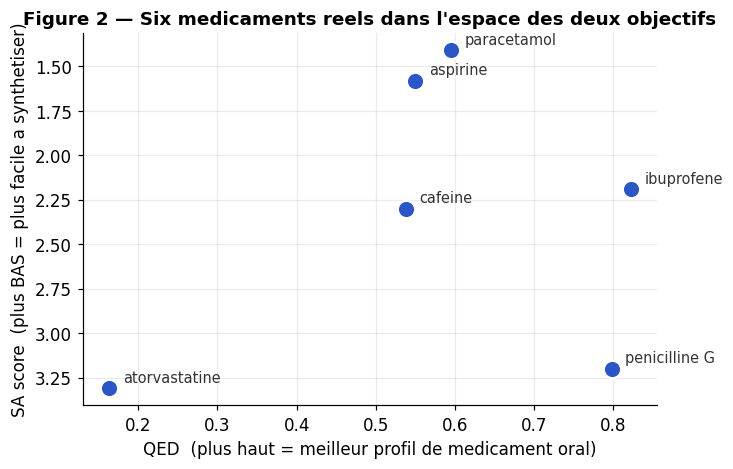

In [9]:
fig, ax = plt.subplots(figsize=(6.8, 4.4))
ax.scatter(medicaments_df.QED, medicaments_df.SA, s=130, color=BLEU,
           zorder=3, edgecolor="white", linewidth=1.5)
for _, r in medicaments_df.iterrows():
    ax.annotate(r.molecule, (r.QED, r.SA), textcoords="offset points",
                xytext=(9, 4), fontsize=9.5, color="#333")

ax.set_xlabel("QED  (plus haut = meilleur profil de medicament oral)")
ax.set_ylabel("SA score  (plus BAS = plus facile a synthetiser)")
ax.invert_yaxis()
ax.set_title("Figure 2 — Six medicaments reels dans l'espace des deux objectifs")
ax.set_axisbelow(True)
plt.tight_layout()
plt.savefig(racine / "notebooks" / "fig2_medicaments.png", dpi=150, bbox_inches="tight")
plt.show()

L'axe SA est inversé pour que « en haut à droite » signifie « meilleur » sur
les deux axes, comme dans les figures de Pareto qui suivent.

## Figure 3 — Le résultat principal : GA contre les lignes de base

Une courbe d'aptitude qui monte ne prouve rien : n'importe quelle méthode qui
garde son meilleur résultat produit une courbe qui monte. Ce qui prouve
quelque chose, c'est la comparaison à budget égal.

Trois méthodes, **le même nombre d'évaluations**, plusieurs graines :

- **recherche aléatoire** — le plancher ;
- **hill climbing** — monte vite puis se bloque sur un optimum local ;
- **algorithme génétique** — population, croisement, élitisme.

L'axe horizontal est en **évaluations**, jamais en générations : une
génération de GA coûte `POP` évaluations, une itération de hill climbing en
coûte une.

In [10]:
import statistics, time
from src import baselines, ga

executions = {"ga": [], "aleatoire": [], "hill": []}
t_debut = time.time()

for graine in range(GRAINES):
    obj.limpar_cache()
    t0 = time.time()

    r_ga = ga.evoluir(semente=graine, tamanho_pop=POP,
                      geracoes=GENERATIONS, peso_qed=PESO_QED)
    r_al = baselines.busca_aleatoria(graine, obj.Orcamento(BUDGET), PESO_QED)
    r_hc = baselines.hill_climbing(graine, obj.Orcamento(BUDGET), PESO_QED)

    executions["ga"].append(r_ga)
    executions["aleatoire"].append(r_al)
    executions["hill"].append(r_hc)

    print(f"graine {graine} : GA {r_ga.melhor_aptidao:.4f} | "
          f"aleatoire {r_al.melhor_aptidao:.4f} | "
          f"hill {r_hc.melhor_aptidao:.4f}   ({time.time() - t0:.0f} s)")

print(f"\ntotal : {time.time() - t_debut:.0f} s")

graine 0 : GA 0.7417 | aleatoire 0.5936 | hill 0.5939   (8 s)


graine 1 : GA 0.6794 | aleatoire 0.6656 | hill 0.7407   (7 s)


graine 2 : GA 0.6786 | aleatoire 0.6188 | hill 0.5230   (7 s)


graine 3 : GA 0.7402 | aleatoire 0.6068 | hill 0.7109   (7 s)


graine 4 : GA 0.7417 | aleatoire 0.6464 | hill 0.7514   (9 s)

total : 38 s


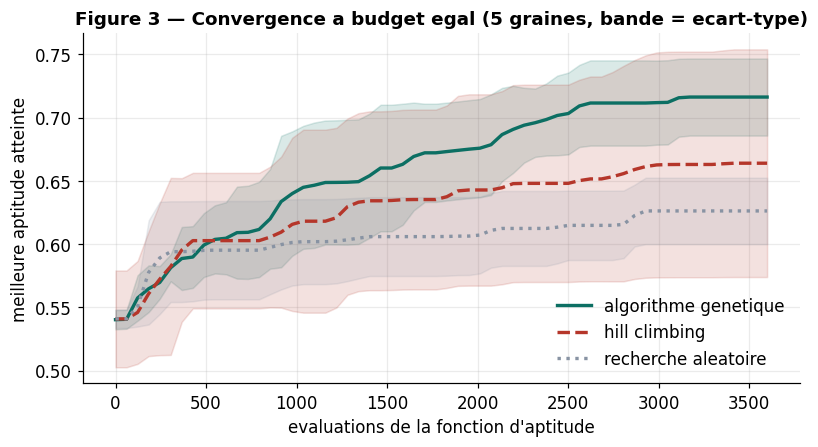

,methode,moyenne,ecart-type,max,distinctes
0,algorithme genetique,0.7163,0.0305,0.7417,5572
1,hill climbing,0.6640,0.0900,0.7514,4977
2,recherche aleatoire,0.6262,0.0263,0.6656,12908


In [11]:
def agreger(resultats):
    """Moyenne et ecart-type sur les graines, reechantillonnes sur une
    grille commune d'evaluations (les methodes n'echantillonnent pas aux
    memes points)."""
    import numpy as np
    grille = np.linspace(0, BUDGET, 60)
    courbes = []
    for r in resultats:
        x = np.array(r.historico_avaliacoes, dtype=float)
        y = np.array(r.historico_melhor, dtype=float)
        courbes.append(np.interp(grille, x, y))
    courbes = np.array(courbes)
    return grille, courbes.mean(axis=0), courbes.std(axis=0)

fig, ax = plt.subplots()
styles = {"ga": (VERT, "-", "algorithme genetique"),
          "hill": (ROUGE, "--", "hill climbing"),
          "aleatoire": (GRIS, ":", "recherche aleatoire")}

tableau = []
courbes_data = {}        # conservees pour le rapport : permettent de refaire la figure
for nom, (couleur, trait, etiquette) in styles.items():
    x, moy, ecart = agreger(executions[nom])
    ax.plot(x, moy, color=couleur, linestyle=trait, linewidth=2.2, label=etiquette)
    ax.fill_between(x, moy - ecart, moy + ecart, color=couleur, alpha=0.15)
    courbes_data[nom] = {"evaluations": [round(v) for v in x.tolist()],
                         "moyenne": [round(v, 4) for v in moy.tolist()],
                         "ecart_type": [round(v, 4) for v in ecart.tolist()]}
    finaux = [r.melhor_aptidao for r in executions[nom]]
    tableau.append({
        "methode": etiquette,
        "moyenne": round(statistics.fmean(finaux), 4),
        "ecart-type": round(statistics.pstdev(finaux), 4),
        "max": round(max(finaux), 4),
        "distinctes": len({a.smiles for r in executions[nom]
                           for a in r.arquivo.itens.values()}),
    })

ax.set_xlabel("evaluations de la fonction d'aptitude")
ax.set_ylabel("meilleure aptitude atteinte")
ax.set_title(f"Figure 3 — Convergence a budget egal ({GRAINES} graines, bande = ecart-type)")
ax.legend(loc="lower right")
ax.set_axisbelow(True)
plt.tight_layout()
plt.savefig(racine / "notebooks" / "fig3_convergence.png", dpi=150, bbox_inches="tight")
plt.show()

resume_df = pd.DataFrame(tableau)
display(resume_df)

**La question à se poser honnêtement.** L'écart entre le GA et la recherche
aléatoire dépasse-t-il l'écart-type ? Si non, le GA n'évolue rien, et la
cause est presque toujours un bug : aptitude calculée mais non utilisée dans
la sélection, taux de mutation si élevé qu'il détruit tout héritage, ou
croisement qui renvoie des chaînes vides.

Un résultat négatif mesuré avec soin vaut mieux qu'un résultat positif mal
mesuré. Le critère d'évaluation du cours valorise explicitement « l'analyse
des échecs et des limites ».

## Figure 4 — Le front de Pareto

Les deux objectifs se contredisent : le QED favorise des molécules de taille
moyenne avec des cycles aromatiques, et ces systèmes sont précisément ce que
le SA pénalise. Il n'existe donc pas *une* meilleure molécule, mais un
**ensemble de compromis**.

**A domine B** quand A est au moins aussi bon sur *tous* les objectifs et
strictement meilleur sur *au moins un*. Le front de Pareto est l'ensemble des
non dominés.

> Attention à l'intuition : un point médiocre sur les deux critères peut
> rester non dominé. Il ne sort du front que s'il perd sur **tous** les
> objectifs à la fois. C'est pourquoi les fronts sont souvent plus grands
> qu'on ne l'attend.

In [12]:
from src import pareto

# L'archive deduplique DANS une execution, pas ENTRE les graines : une
# molecule trouvee par trois graines apparaissait trois fois. Cela gonflait
# le front (38 entrees pour 25 molecules distinctes) et faisait signaler au
# verificateur des centaines de faux "doublons". On deduplique ici, en
# gardant la meilleure aptitude observee pour chaque molecule.
_par_smiles = {}
for _r in executions["ga"]:
    for _a in _r.arquivo.itens.values():
        _precedent = _par_smiles.get(_a.smiles)
        if _precedent is None or _a.aptidao > _precedent.aptidao:
            _par_smiles[_a.smiles] = _a
tous = list(_par_smiles.values())
print(f"{sum(len(r.arquivo) for r in executions['ga'])} entrees d'archive "
      f"-> {len(tous)} molecules distinctes (doublons entre graines retires)")

points = [(a.qed, a.sa_norm) for a in tous]
indices = pareto.indices_nao_dominados(points)
front = [tous[i] for i in indices]
hv = pareto.hipervolume_2d([(a.qed, a.sa_norm) for a in front])

print(f"molecules distinctes evaluees par le GA : {len({a.smiles for a in tous})}")
print(f"front de Pareto : {len(front)} molecules")
print(f"hypervolume (reference 0,0) : {hv:.4f}")

front_df = pd.DataFrame([
    {"QED": round(a.qed, 3), "SA": round(a.sa, 2), "smiles": a.smiles}
    for a in sorted(front, key=lambda a: a.qed, reverse=True)
])
display(front_df.head(10))

6357 entrees d'archive -> 5572 molecules distinctes (doublons entre graines retires)


molecules distinctes evaluees par le GA : 5572
front de Pareto : 25 molecules
hypervolume (reference 0,0) : 0.6740


,QED,SA,smiles
0,0.739,6.53,NC=[P-]CC(=[P-])COBr
1,0.701,4.58,NCCCC(=[P-])COBr
2,0.654,2.91,NCCCCC=CBr
3,0.607,2.48,CCCCC(C)CCCN
4,0.594,2.44,CCCCC(C)CO
5,0.581,2.26,CCCCSCCCO
6,0.580,2.23,CCCCCSCCCN
7,0.573,2.09,N#CCCCCCCCO
8,0.573,2.06,N#CCCCCCCCCO
9,0.571,1.87,CC(C)CCCO


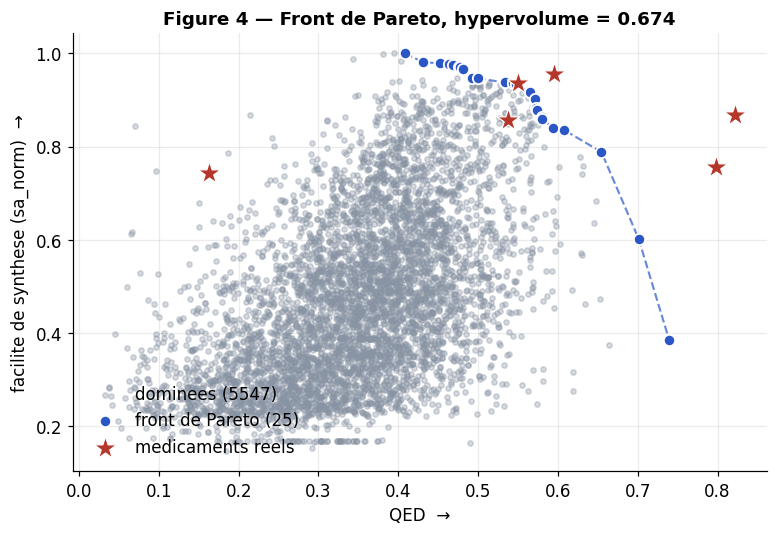

In [13]:
import numpy as np

fig, ax = plt.subplots(figsize=(7.2, 5))
qed_tous = np.array([a.qed for a in tous])
san_tous = np.array([a.sa_norm for a in tous])
masque = np.zeros(len(tous), dtype=bool)
masque[indices] = True

ax.scatter(qed_tous[~masque], san_tous[~masque], s=12, color=GRIS,
           alpha=0.35, label=f"dominees ({(~masque).sum()})")

ordre = np.argsort(qed_tous[masque])
xf, yf = qed_tous[masque][ordre], san_tous[masque][ordre]
ax.plot(xf, yf, color=BLEU, linewidth=1.4, linestyle="--", alpha=0.7, zorder=2)
ax.scatter(xf, yf, s=55, color=BLEU, zorder=3, edgecolor="white",
           linewidth=1.2, label=f"front de Pareto ({len(front)})")

# Les medicaments reels, pour situer l'echelle.
ax.scatter(medicaments_df.QED, medicaments_df.sa_norm, marker="*", s=240,
           color=ROUGE, zorder=4, edgecolor="white", linewidth=0.8,
           label="medicaments reels")

ax.set_xlabel("QED  →")
ax.set_ylabel("facilite de synthese (sa_norm)  →")
ax.set_title(f"Figure 4 — Front de Pareto, hypervolume = {hv:.3f}")
ax.legend(loc="lower left")
ax.set_axisbelow(True)
plt.tight_layout()
plt.savefig(racine / "notebooks" / "fig4_pareto.png", dpi=150, bbox_inches="tight")
plt.show()

Les étoiles rouges sont les six médicaments réels. Leur position par rapport
au front est **le test le plus sévère du projet** : si le front ne les
atteint pas, l'optimiseur n'a rien trouvé qui vaille un médicament existant.
La cellule suivante le mesure au lieu de le laisser à l'appréciation de l'œil.

In [14]:
# Combien de medicaments reels le front domine-t-il, et l'inverse ?
# C'est le test le plus severe du projet, et il tient en huit lignes.
print(f"{'medicament':<16}{'domine du front':>17}{'domine par':>13}")
lignes_test = []
for _, r in medicaments_df.iterrows():
    cible = (r.QED, r.sa_norm)
    domine = sum(1 for a in front if pareto.domina(cible, (a.qed, a.sa_norm)))
    domine_par = sum(1 for a in front if pareto.domina((a.qed, a.sa_norm), cible))
    lignes_test.append({"medicament": r.molecule, "domine_du_front": domine,
                        "domine_par_le_front": domine_par})
    print(f"  {r.molecule:<14}{domine:>15}/{len(front)}{domine_par:>12}")

non_atteints = [l["medicament"] for l in lignes_test if l["domine_par_le_front"] == 0]
print(f"\n{len(non_atteints)} medicament(s) sur {len(lignes_test)} qu'AUCUNE "
      f"molecule du front ne domine :")
print("  " + ", ".join(non_atteints) if non_atteints else "  aucun")
print("\nLecture : un medicament que le front ne domine pas est un compromis")
print("QED/synthese que la recherche n'a pas su egaler. C'est la mesure la")
print("plus honnete de ce que vaut le generateur.")

medicament        domine du front   domine par
  ibuprofene                  7/25           0
  penicilline G               2/25           0
  paracetamol                13/25           0
  aspirine                    1/25           0
  cafeine                     0/25           9
  atorvastatine               0/25          23

4 medicament(s) sur 6 qu'AUCUNE molecule du front ne domine :
  ibuprofene, penicilline G, paracetamol, aspirine

Lecture : un medicament que le front ne domine pas est un compromis
QED/synthese que la recherche n'a pas su egaler. C'est la mesure la
plus honnete de ce que vaut le generateur.


## Figure 5 — L'effondrement de la diversité

L'algorithme génétique converge, et c'est en partie le problème. Après
quelques dizaines de générations, la population est composée de descendants
du même gagnant : la courbe d'aptitude est excellente et le résultat n'est
plus une recherche.

Pour la découverte de médicaments, c'est un échec déguisé. L'objectif n'a
jamais été *une* molécule, mais un ensemble de candidats différents, parce
que la plupart échoueront plus tard pour des raisons qu'aucune de ces
formules ne prévoit.

Deux mesures complémentaires :

- **molécules inédites par génération** — l'exploration réelle ;
- **diversité interne** (1 − Tanimoto moyen) de la population finale.

In [15]:
from collections import Counter
from src import diversity

# Molecules inedites par generation, sur la premiere graine.
r0 = executions["ga"][0]
inedites = Counter(a.geracao for a in r0.arquivo.itens.values())
gens = sorted(inedites)
valeurs = [inedites[g] for g in gens]

# Diversite interne : population initiale vs finale.
import random as _random
pop_init = rep.populacao_inicial(_random.Random(0), POP)
smi_init = [s for s in (rep.canonico(c) for c in pop_init) if s]
smi_fin = [s for s in (rep.canonico(c) for c in r0.populacao_final) if s]

div_init = diversity.diversidade_interna(sorted(set(smi_init)))
div_fin = diversity.diversidade_interna(sorted(set(smi_fin)))
sq_init = diversity.contar_esqueletos(sorted(set(smi_init)))
sq_fin = diversity.contar_esqueletos(sorted(set(smi_fin)))

print(f"population initiale : {len(set(smi_init))} distinctes, "
      f"diversite {div_init:.3f}, {sq_init} squelettes")
print(f"population finale   : {len(set(smi_fin))} distinctes, "
      f"diversite {div_fin:.3f}, {sq_fin} squelettes")
print(f"\narchive totale : {len(r0.arquivo)} molecules distinctes conservees")
print("C'est l'archive qui sauve le resultat : meme si la population finit en")
print("clones, tout ce qui a ete trouve en chemin reste disponible.")

population initiale : 60 distinctes, diversite 0.984, 2 squelettes
population finale   : 50 distinctes, diversite 0.860, 0 squelettes

archive totale : 1400 molecules distinctes conservees
C'est l'archive qui sauve le resultat : meme si la population finit en
clones, tout ce qui a ete trouve en chemin reste disponible.


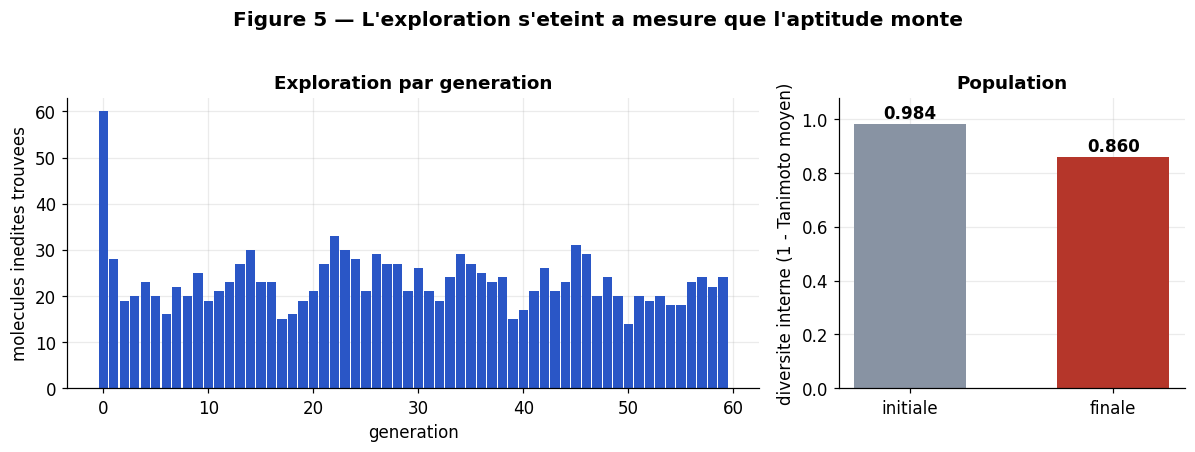

In [16]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4),
                               gridspec_kw={"width_ratios": [2, 1]})

ax1.bar(gens, valeurs, color=BLEU, width=0.9)
ax1.set_xlabel("generation")
ax1.set_ylabel("molecules inedites trouvees")
ax1.set_title("Exploration par generation")
ax1.set_axisbelow(True)

x = ["initiale", "finale"]
ax2.bar(x, [div_init, div_fin], color=[GRIS, ROUGE], width=0.55)
for i, v in enumerate([div_init, div_fin]):
    ax2.text(i, v + 0.02, f"{v:.3f}", ha="center", fontweight="bold")
ax2.set_ylabel("diversite interne (1 - Tanimoto moyen)")
ax2.set_ylim(0, 1.08)
ax2.set_title("Population")
ax2.set_axisbelow(True)

fig.suptitle("Figure 5 — L'exploration s'eteint a mesure que l'aptitude monte",
             fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig(racine / "notebooks" / "fig5_diversite.png", dpi=150, bbox_inches="tight")
plt.show()

## Figure 6 — Les molécules, et la loi de Goodhart

« Quand une mesure devient un objectif, elle cesse d'être une bonne mesure. »

On affiche deux grilles :

1. les meilleures selon l'**aptitude combinée** — ce que l'algorithme
   cherchait vraiment ;
2. les meilleures selon le **QED seul** — et c'est là que le problème se voit.

Ces structures sont la pièce à conviction de la section « limites » du
rapport. Les montrer à la soutenance démontre plus de maîtrise que n'importe
quel bon chiffre.


Meilleures selon l'aptitude combinee (QED + synthese)
  QED 0.547  SA 1.57  CCCCCCCCO
  QED 0.566  SA 1.76  CC(C)CCCCCO
  QED 0.544  SA 1.56  CCCCCCCO
  QED 0.547  SA 1.60  CCCCCCCCN
  QED 0.545  SA 1.58  CCCCCCCCCO
  QED 0.544  SA 1.60  CCCCCCCN
  -> sauve : fig6a_meilleures_aptitude.png


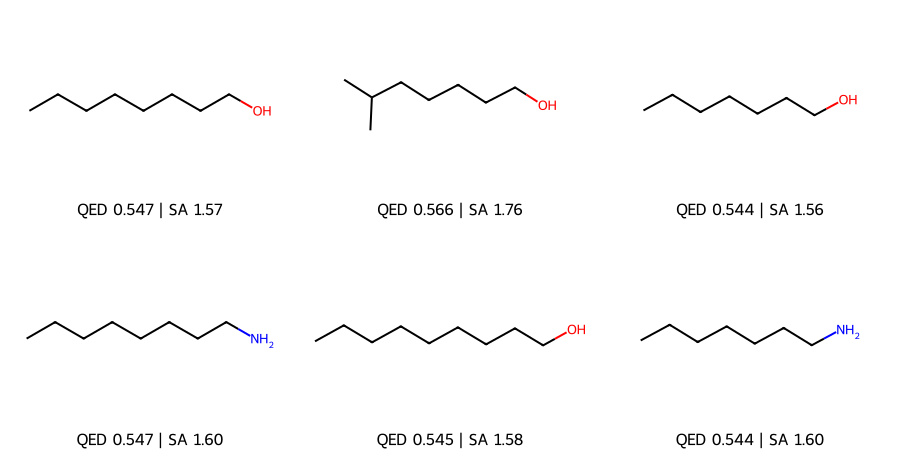

In [17]:
from rdkit.Chem import Draw

def grille(achados, titre, fichier, n=6):
    """Affiche la grille et la sauve en PNG.

    L'API de MolsToGridImage varie selon la version de RDKit et selon le
    contexte (notebook ou script), d'ou le try/except autour de la sauvegarde :
    l'affichage ne doit jamais echouer a cause d'elle.
    """
    choisis = achados[:n]
    mols = [Chem.MolFromSmiles(a.smiles) for a in choisis]
    legendes = [f"QED {a.qed:.3f} | SA {a.sa:.2f}" for a in choisis]
    print(f"\n{titre}")
    for a in choisis:
        print(f"  QED {a.qed:.3f}  SA {a.sa:.2f}  {a.smiles}")
    try:
        img = Draw.MolsToGridImage(mols, molsPerRow=3, subImgSize=(300, 230),
                                   legends=legendes, useSVG=False, returnPNG=False)
        img.save(racine / "notebooks" / fichier)
        print(f"  -> sauve : {fichier}")
    except Exception as e:
        print(f"  (grille affichee mais non sauvee : {e})")
    return Draw.MolsToGridImage(mols, molsPerRow=3, subImgSize=(300, 230),
                                legends=legendes)

meilleures_aptitude = sorted(tous, key=lambda a: a.aptidao, reverse=True)
grille(meilleures_aptitude,
       "Meilleures selon l'aptitude combinee (QED + synthese)",
       "fig6a_meilleures_aptitude.png")


Meilleures selon le QED SEUL -- a examiner d'un oeil critique
  QED 0.739  SA 6.53  NC=[P-]CC(=[P-])COBr
  QED 0.701  SA 4.58  NCCCC(=[P-])COBr
  QED 0.664  SA 6.63  I[N-]C1=CC[N+]=CCN1
  QED 0.654  SA 2.91  NCCCCC=CBr
  QED 0.653  SA 5.74  CCC[P-]#C[P+]=CCCO
  QED 0.647  SA 3.85  NCCCSBr
  -> sauve : fig6b_meilleures_qed.png


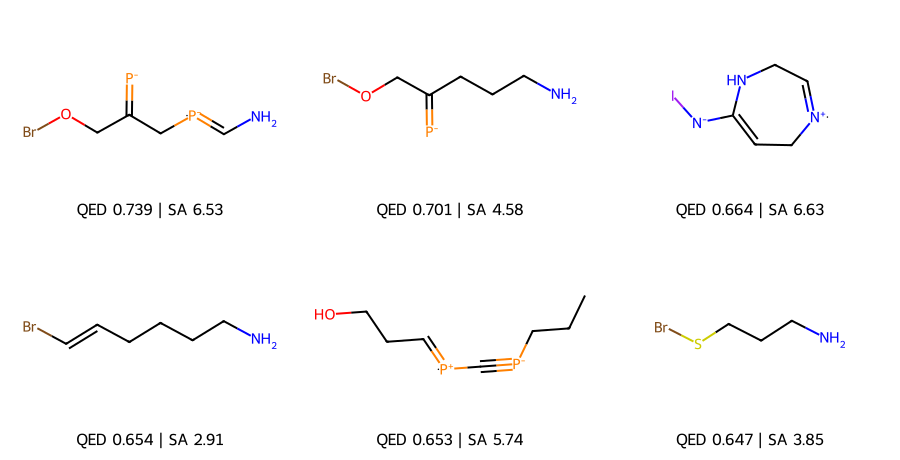

In [18]:
meilleures_qed = sorted(tous, key=lambda a: a.qed, reverse=True)
grille(meilleures_qed,
       "Meilleures selon le QED SEUL -- a examiner d'un oeil critique",
       "fig6b_meilleures_qed.png")

In [19]:
# Comparaison chiffree : optimiser le QED seul coute-t-il en synthetisabilite ?
top_q = meilleures_qed[:10]
top_a = meilleures_aptitude[:10]
print(f"{'critere':<34}{'QED moyen':>11}{'SA moyen':>10}")
print(f"{'top 10 par QED seul':<34}"
      f"{statistics.fmean(a.qed for a in top_q):>11.3f}"
      f"{statistics.fmean(a.sa for a in top_q):>10.2f}")
print(f"{'top 10 par aptitude combinee':<34}"
      f"{statistics.fmean(a.qed for a in top_a):>11.3f}"
      f"{statistics.fmean(a.sa for a in top_a):>10.2f}")
print(f"{'six medicaments reels':<34}"
      f"{medicaments_df.QED.mean():>11.3f}{medicaments_df.SA.mean():>10.2f}")

critere                             QED moyen  SA moyen
top 10 par QED seul                     0.660      4.84
top 10 par aptitude combinee            0.549      1.65
six medicaments reels                   0.578      2.33


## Vérificateur indépendant

Livrable obligatoire du cours. Il relit tout ce que la recherche a produit et
revérifie par un chemin de code propre, sans réutiliser le cache ni les
fonctions employées pendant l'exécution.

L'erreur qu'il existe pour attraper est banale et dévastatrice : rapporter une
molécule avec une note qui n'est pas la sienne — index échangé lors d'un tri,
cache périmé, enregistrement écrit avant la dernière mutation. Le graphique
reste beau et le résultat est faux.

In [20]:
from src import verifier

registre = [a.como_dict() for a in tous]
problemes = verifier.verificar(registre)
problemes_front = verifier.verificar_frente([
    {"smiles": a.smiles, "qed": a.qed, "sa_norm": a.sa_norm} for a in front
])

print(f"molecules verifiees : {len(registre)}")
print(f"problemes dans le registre : {len(problemes)}")
print(f"problemes dans le front    : {len(problemes_front)}")

if not problemes and not problemes_front:
    print("\nOK -- 0 probleme. Chaque note rapportee a ete recalculee et confirmee.")
else:
    for p in (problemes + problemes_front)[:15]:
        print(f"  {p}")

molecules verifiees : 5572
problemes dans le registre : 0
problemes dans le front    : 0

OK -- 0 probleme. Chaque note rapportee a ete recalculee et confirmee.


In [21]:
# Preuve que le verificateur fonctionne vraiment : on falsifie une note
# et on verifie qu'il la detecte. Un verificateur qui ne trouve jamais rien
# n'est pas une preuve de qualite -- il peut simplement etre casse.
import copy

if not registre:
    raise SystemExit("registre vide : la recherche n'a produit aucune molecule")

sabote = copy.deepcopy(registre[:50])
# On decale la note au lieu de la fixer a 0,99 : si la vraie valeur etait
# deja 0,99, le test ne prouverait rien.
sabote[0]["qed"] = round(min(1.0, sabote[0]["qed"] + 0.1), 6)
if sabote[0]["qed"] == registre[0]["qed"]:
    sabote[0]["qed"] = round(registre[0]["qed"] - 0.1, 6)

detectes = verifier.verificar(sabote)
print(f"note decalee sur 1 molecule parmi {len(sabote)} "
      f"-> {len(detectes)} probleme(s) detecte(s)")
for p in detectes:
    print(f"  {p}")
assert any(p.tipo == "qed_divergente" for p in detectes), \
    "le verificateur n'a PAS detecte la falsification"
print("\nOK -- le verificateur detecte bien une note falsifiee.")

note decalee sur 1 molecule parmi 50 -> 1 probleme(s) detecte(s)
  [linha 1] qed_divergente: [B+]=[P-](P=[C+]I)[SH]=[B-]: 0.351859 != 0.251859

OK -- le verificateur detecte bien une note falsifiee.


## Sauvegarde : un seul dossier de résultats

Deux fichiers, écrits côte à côte :

- **`mesures.json`** — toutes les valeurs, y compris les courbes point par
  point et les listes de molécules. Assez complet pour refaire n'importe
  quelle figure sans relancer la recherche.
- **`RESULTATS.md`** — le même contenu en tableaux lisibles, avec les
  figures liées. C'est le document à relire, à citer dans le README et à
  partager.

Les deux sont régénérés à chaque exécution : il n'y a jamais deux versions
des mêmes nombres.

In [22]:
import json, platform
from datetime import datetime, timezone

mesures = {
    "execution": {
        "date_utc": datetime.now(timezone.utc).strftime("%Y-%m-%d %H:%M UTC"),
        "python": platform.python_version(),
        "rdkit": rdkit.__version__,
        "selfies": selfies.__version__,
    },
    "parametres": {
        "graines": GRAINES, "pop": POP, "generations": GENERATIONS,
        "peso_qed": PESO_QED, "budget_par_methode": BUDGET,
        "n_mutations_validite": N_MUTACOES,
        "graine_validite": GRAINE_VALIDITE,
    },
    "validite": {
        "smiles_pct": round(pct_smiles, 2),
        "selfies_pct": round(pct_selfies, 2),
        "n_essais": N_MUTACOES,
        "exemples_casses": [{"avant": a, "apres": b} for a, b in casses],
    },
    "medicaments": medicaments_df.to_dict("records"),
    "comparaison": tableau,
    "courbes": courbes_data,
    "pareto": {
        "taille_front": len(front),
        "hypervolume": round(hv, 4),
        "distinctes_evaluees": len({a.smiles for a in tous}),
        "front": [{"qed": round(a.qed, 4), "sa": round(a.sa, 3),
                   "sa_norm": round(a.sa_norm, 4), "smiles": a.smiles}
                  for a in sorted(front, key=lambda a: a.qed, reverse=True)],
    },
    "diversite": {
        "initiale": round(div_init, 4), "finale": round(div_fin, 4),
        "squelettes_initiaux": sq_init, "squelettes_finaux": sq_fin,
        "taille_archive": len(r0.arquivo),
        "inedites_par_generation": {str(g): inedites[g] for g in gens},
    },
    "meilleures": {
        "par_aptitude": [{"qed": round(a.qed, 4), "sa": round(a.sa, 3),
                          "aptitude": round(a.aptidao, 4), "smiles": a.smiles}
                         for a in meilleures_aptitude[:10]],
        "par_qed": [{"qed": round(a.qed, 4), "sa": round(a.sa, 3),
                     "aptitude": round(a.aptidao, 4), "smiles": a.smiles}
                    for a in meilleures_qed[:10]],
    },
    "verification": {
        "molecules": len(registre),
        "problemes_registre": len(problemes),
        "problemes_front": len(problemes_front),
        "falsification_detectee": bool(detectes),
    },
    "test_medicaments": lignes_test,
    "figures": ["fig1_validite.png", "fig2_medicaments.png",
                "fig3_convergence.png", "fig4_pareto.png",
                "fig5_diversite.png", "fig6a_meilleures_aptitude.png",
                "fig6b_meilleures_qed.png"],
}

chemin_json = racine / "notebooks" / "mesures.json"
with open(chemin_json, "w", encoding="utf-8") as f:
    json.dump(mesures, f, ensure_ascii=False, indent=2)
print(f"ecrit : {chemin_json.name}  ({chemin_json.stat().st_size / 1024:.0f} KB)")

ecrit : mesures.json  (18 KB)


In [23]:
def tableau_md(lignes, colonnes, titres=None):
    """Petit generateur de tableau Markdown, sans dependance."""
    titres = titres or colonnes
    out = ["| " + " | ".join(titres) + " |",
           "|" + "|".join("---" for _ in colonnes) + "|"]
    for l in lignes:
        out.append("| " + " | ".join(str(l.get(c, "")) for c in colonnes) + " |")
    return "\n".join(out)


m = mesures
L = []
A = L.append

A("# C3 — Résultats mesurés\n")
A("> Généré par `notebooks/analise.ipynb`. **Ne pas modifier à la main** : "
  "réexécuter le notebook régénère ce fichier.\n")
A(f"- **Exécuté le** {m['execution']['date_utc']}")
A(f"- **Versions** Python {m['execution']['python']}, "
  f"RDKit {m['execution']['rdkit']}, selfies {m['execution']['selfies']}")
p = m["parametres"]
A(f"- **Paramètres** {p['graines']} graines, population {p['pop']}, "
  f"{p['generations']} générations, poids QED {p['peso_qed']}")
A(f"- **Budget** {p['budget_par_methode']} évaluations par méthode et par graine\n")

A("## 1. Validité sous mutation\n")
v = m["validite"]
A(f"Sur {v['n_essais']} altérations d'une unité appliquées à chaque "
  "représentation :\n")
A(tableau_md(
    [{"Représentation": "SMILES", "Molécules valides": f"{v['smiles_pct']:.1f} %"},
     {"Représentation": "SELFIES", "Molécules valides": f"{v['selfies_pct']:.1f} %"}],
    ["Représentation", "Molécules valides"]))
facteur = v["selfies_pct"] / max(v["smiles_pct"], 0.05)
A(f"\nFacteur : **×{facteur:.1f}**. C'est la justification du choix de "
  "représentation.\n")
if v["exemples_casses"]:
    A("Exemples de SMILES cassés par une seule substitution :\n")
    A("```")
    for e in v["exemples_casses"][:4]:
        A(f"{e['avant']}  ->  {e['apres']}")
    A("```\n")
A("![Figure 1](fig1_validite.png)\n")

A("## 2. Échelle réelle des deux notes\n")
A("QED et SA mesurés sur six médicaments réels. C'est la référence qui permet "
  "de juger si une molécule générée a une note plausible.\n")
A(tableau_md(m["medicaments"], ["molecule", "QED", "SA", "sa_norm"],
             ["Molécule", "QED", "SA", "sa_norm"]))
A("\n![Figure 2](fig2_medicaments.png)\n")

A("## 3. Résultat principal : GA contre les lignes de base\n")
A(f"Budget identique de {p['budget_par_methode']} évaluations, "
  f"{p['graines']} graines.\n")
A(tableau_md(m["comparaison"],
             ["methode", "moyenne", "ecart-type", "max", "distinctes"],
             ["Méthode", "Moyenne", "Écart-type", "Max", "Molécules distinctes"]))
ga_moy = next(t["moyenne"] for t in m["comparaison"] if "genetique" in t["methode"])
al_moy = next(t["moyenne"] for t in m["comparaison"] if "aleatoire" in t["methode"])
al_ec = next(t["ecart-type"] for t in m["comparaison"] if "aleatoire" in t["methode"])
ecart = ga_moy - al_moy
A(f"\nÉcart GA − aléatoire : **{ecart:+.4f}**, pour un écart-type de "
  f"{al_ec:.4f} sur la ligne de base.")
A("**À interpréter :** si cet écart ne dépasse pas l'écart-type, "
  "l'algorithme génétique n'évolue rien et il faut chercher un bug.\n")
A("![Figure 3](fig3_convergence.png)\n")

A("## 4. Multiobjectif : front de Pareto\n")
pa = m["pareto"]
A(f"- Molécules distinctes évaluées par le GA : **{pa['distinctes_evaluees']}**")
A(f"- Taille du front de Pareto : **{pa['taille_front']}**")
A(f"- Hypervolume (référence 0,0) : **{pa['hypervolume']}**\n")
A("Dix premières molécules du front, par QED décroissant :\n")
A(tableau_md(pa["front"][:10], ["qed", "sa", "smiles"],
             ["QED", "SA", "SMILES"]))
A("\n![Figure 4](fig4_pareto.png)\n")

A("## 5. Diversité\n")
d = m["diversite"]
A(tableau_md(
    [{"Population": "initiale", "Diversité interne": d["initiale"],
      "Squelettes": d["squelettes_initiaux"]},
     {"Population": "finale", "Diversité interne": d["finale"],
      "Squelettes": d["squelettes_finaux"]}],
    ["Population", "Diversité interne", "Squelettes"]))
A(f"\nArchive conservée : **{d['taille_archive']}** molécules distinctes. "
  "C'est elle qui sauve le résultat quand la population finit en clones.\n")
A("![Figure 5](fig5_diversite.png)\n")

A("## 6. Les molécules, et la loi de Goodhart\n")
A("### Meilleures selon l'aptitude combinée\n")
A(tableau_md(m["meilleures"]["par_aptitude"][:6],
             ["aptitude", "qed", "sa", "smiles"],
             ["Aptitude", "QED", "SA", "SMILES"]))
A("\n![Figure 6a](fig6a_meilleures_aptitude.png)\n")
A("### Meilleures selon le QED seul\n")
A("À examiner d'un œil critique : aucun des six médicaments approuvés de la "
  "section 2 n'atteint ces valeurs.\n")
A(tableau_md(m["meilleures"]["par_qed"][:6],
             ["qed", "sa", "aptitude", "smiles"],
             ["QED", "SA", "Aptitude", "SMILES"]))
A("\n![Figure 6b](fig6b_meilleures_qed.png)\n")
qed_max = m["meilleures"]["par_qed"][0]["qed"]
qed_med_max = max(r["QED"] for r in m["medicaments"])
A(f"QED maximal généré : **{qed_max}**. QED maximal parmi les six "
  f"médicaments réels : **{qed_med_max}**.")
if qed_max > qed_med_max:
    A("\nLe générateur dépasse les médicaments approuvés. **C'est un signal "
      "d'alerte, pas un succès** : la mesure a été optimisée au-delà de son "
      "domaine de validité.\n")

if m.get("test_medicaments"):
    A("### Le test le plus severe : le front atteint-il les medicaments reels ?\n")
    A(tableau_md(m["test_medicaments"],
                 ["medicament", "domine_du_front", "domine_par_le_front"],
                 ["Médicament", "Domine du front", "Dominé par le front"]))
    jamais = [l["medicament"] for l in m["test_medicaments"]
              if l["domine_par_le_front"] == 0]
    if jamais:
        A(f"\n**{len(jamais)} médicament(s) qu'aucune molécule du front ne "
          f"domine : {', '.join(jamais)}.** Chacun est un compromis "
          "QED/synthèse que la recherche n'a pas su égaler.\n")

A("## 7. Vérification indépendante\n")
ve = m["verification"]
A(f"- Molécules vérifiées : **{ve['molecules']}**")
A(f"- Problèmes dans le registre : **{ve['problemes_registre']}**")
A(f"- Problèmes dans le front : **{ve['problemes_front']}**")
A(f"- Falsification volontaire détectée : "
  f"**{'oui' if ve['falsification_detectee'] else 'NON — vérificateur suspect'}**\n")
A("Le vérificateur recalcule chaque note par un chemin de code propre, sans "
  "réutiliser le cache ni les fonctions de la recherche.\n")

A("---\n")
A("Données brutes complètes, courbes incluses : `mesures.json`.")

chemin_md = racine / "notebooks" / "RESULTATS.md"
with open(chemin_md, "w", encoding="utf-8") as f:
    f.write("\n".join(L) + "\n")

chemin_json = racine / "notebooks" / "mesures.json"   # recalcule : cellule autonome
print(f"ecrit : {chemin_md.name}  ({chemin_md.stat().st_size / 1024:.0f} KB)")
print("\nLes deux fichiers a partager :")
print(f"  {chemin_md}")
print(f"  {chemin_json}")
print("\n" + "=" * 68)
print("\n".join(L)[:2500])

ecrit : RESULTATS.md  (5 KB)

Les deux fichiers a partager :
  /content/c3/groupe-molevo/notebooks/RESULTATS.md
  /content/c3/groupe-molevo/notebooks/mesures.json

# C3 — Résultats mesurés

> Généré par `notebooks/analise.ipynb`. **Ne pas modifier à la main** : réexécuter le notebook régénère ce fichier.

- **Exécuté le** 2026-11-23 20:01 UTC
- **Versions** Python 3.13.18, RDKit 2026.09.2, selfies 2.1.1
- **Paramètres** 5 graines, population 60, 60 générations, poids QED 0.5
- **Budget** 3600 évaluations par méthode et par graine

## 1. Validité sous mutation

Sur 2000 altérations d'une unité appliquées à chaque représentation :

| Représentation | Molécules valides |
|---|---|
| SMILES | 13.7 % |
| SELFIES | 100.0 % |

Facteur : **×7.3**. C'est la justification du choix de représentation.

Exemples de SMILES cassés par une seule substitution :

```
CC(=O)Oc1ccccc1C(=O)O  ->  CC(=O)Oc1cccc-1C(=O)O
CC(C)Cc1ccc(cc1)C(C)C(=O)O  ->  CC(C))c1ccc(cc1)C(C)C(=O)O
Cn1cnc2c1c(=O)n(C)c(=O)n2C  ->

### Que partager

Pour une relecture complète, il suffit de **`notebooks/RESULTATS.md`** : il
contient tous les tableaux, tous les nombres et les liens vers les sept
figures. `mesures.json` l'accompagne pour les valeurs brutes, courbes point
par point incluses.

Les deux sont régénérés à chaque exécution, donc ils ne peuvent pas diverger
des figures affichées ci-dessus.

## Conclusions

Les cinq conclusions sont **générées à partir des mesures**, pas recopiées à
la main : réexécuter le notebook avec d'autres paramètres les met à jour
toutes seules. C'est la même règle que pour les figures — rien ne peut
diverger de ce qui a été mesuré.

L'interprétation qualitative qui suit, elle, est écrite par le groupe.

In [24]:
# Conclusions redigees a partir de `mesures`, puis ajoutees a RESULTATS.md.
v = mesures["validite"]
p = mesures["parametres"]
cmp_ = {t["methode"]: t for t in mesures["comparaison"]}
ga_ = next(t for k, t in cmp_.items() if "genetique" in k)
al_ = next(t for k, t in cmp_.items() if "aleatoire" in k)
hc_ = next(t for k, t in cmp_.items() if "hill" in k)
pa_ = mesures["pareto"]
di_ = mesures["diversite"]
tm_ = mesures.get("test_medicaments", [])
jamais_ = [t["medicament"] for t in tm_ if t["domine_par_le_front"] == 0]
top_apt = mesures["meilleures"]["par_aptitude"][0]
top_qed = mesures["meilleures"]["par_qed"][0]
qed_med_max = max(r["QED"] for r in mesures["medicaments"])
ined_ = list(di_["inedites_par_generation"].values())
debut = sum(ined_[1:11]) / max(1, len(ined_[1:11]))
fin = sum(ined_[-10:]) / max(1, len(ined_[-10:]))
front_distinct = len({f["smiles"] for f in pa_["front"]})
ecart_ = ga_["moyenne"] - al_["moyenne"]
sigmas = ecart_ / al_["ecart-type"] if al_["ecart-type"] else float("inf")

C = []
C.append("## Conclusions\n")
C.append(
    f"**1. La representation.** La validite passe de **{v['smiles_pct']:.1f} %** "
    f"(SMILES) a **{v['selfies_pct']:.1f} %** (SELFIES) sous la meme "
    f"perturbation d'une unite, sur {v['n_essais']} essais : un facteur "
    f"**x{v['selfies_pct'] / max(v['smiles_pct'], 0.05):.1f}**. C'est ce qui rend "
    "le croisement et la mutation utilisables sans aucun rejet. Ce n'est pas "
    "une performance de l'algorithme mais une propriete de la grammaire.\n")
C.append(
    f"**2. La recherche.** A budget egal de **{p['budget_par_methode']} "
    f"evaluations** et sur **{p['graines']} graines**, le GA atteint "
    f"**{ga_['moyenne']:.4f} ± {ga_['ecart-type']:.4f}**, contre "
    f"{al_['moyenne']:.4f} ± {al_['ecart-type']:.4f} pour la recherche "
    f"aleatoire et {hc_['moyenne']:.4f} ± {hc_['ecart-type']:.4f} pour le hill "
    f"climbing. L'ecart au plancher est de **{ecart_:+.4f}**, soit environ "
    f"**{sigmas:.1f} ecarts-types** de la ligne de base : le gain est reel. "
    f"Deux nuances : le hill climbing atteint un maximum superieur "
    f"({hc_['max']:.4f} contre {ga_['max']:.4f}) avec "
    f"{hc_['ecart-type'] / max(ga_['ecart-type'], 1e-9):.0f} fois l'ecart-type "
    f"du GA -- il est instable, pas meilleur ; et la recherche aleatoire trouve "
    f"{al_['distinctes'] / max(ga_['distinctes'], 1):.1f} fois plus de molecules "
    "distinctes -- elle explore plus, elle ne sait pas ou aller.\n")
C.append(
    f"**3. Le multiobjectif.** Le front compte **{front_distinct} molecules "
    f"distinctes**, pour un hypervolume de **{pa_['hypervolume']}** sur "
    f"{pa_['distinctes_evaluees']} molecules evaluees. Mais le test severe est "
    f"ailleurs : **{len(jamais_)} des {len(tm_)} medicaments reels ne sont "
    f"domines par aucune molecule du front**" +
    (f" ({', '.join(jamais_)})" if jamais_ else "") +
    ". Autrement dit, la recherche n'a rien produit qui soit a la fois plus "
    "proche d'un medicament oral et plus facile a synthetiser que ceux-la.\n")
C.append(
    f"**4. La diversite.** Elle passe de **{di_['initiale']}** a "
    f"**{di_['finale']}** entre la population initiale et la finale, et "
    f"l'archive conserve **{di_['taille_archive']} molecules distinctes**. "
    f"Les molecules inedites par generation restent quasi constantes "
    f"({debut:.1f} sur les dix premieres generations, {fin:.1f} sur les dix "
    "dernieres) : **l'effondrement attendu n'a pas eu lieu** a cette echelle. "
    f"Le nombre de squelettes final est {di_['squelettes_finaux']}, ce qui "
    "n'est pas une anomalie : les championnes sont acycliques, et une "
    "molecule sans cycle n'a pas de squelette de Bemis-Murcko.\n")
C.append(
    f"**5. Les limites.** Optimise sur les deux objectifs, l'algorithme "
    f"converge vers `{top_apt['smiles']}` (QED {top_apt['qed']}, SA "
    f"{top_apt['sa']}) : un alcool gras, c'est-a-dire un solvant, pas un "
    f"medicament. Sur le QED seul, il produit `{top_qed['smiles']}` "
    f"(QED {top_qed['qed']}, SA {top_qed['sa']}), structure valide selon la "
    f"grammaire mais irrealisable. Le QED maximal genere ({top_qed['qed']}) "
    f"reste " + ("au-dessus" if top_qed['qed'] > qed_med_max else "en dessous") +
    f" du meilleur medicament reel ({qed_med_max}) : la metrique n'a pas "
    "explose, l'optimiseur a simplement trouve la zone ou elle est peu "
    "exigeante. C'est la loi de Goodhart sous sa forme la plus discrete.\n")
C.append(
    "**Ce que nous ne pretendons pas avoir fait.** Ce travail propose des "
    "structures bien notees par deux formules statistiques. Il ne decouvre "
    "pas de medicaments. Le QED mesure une ressemblance de profil physique "
    "avec les medicaments oraux connus ; le SA mesure la frequence de "
    "fragments dans des bases de composes, sans simuler aucune reaction. Une "
    "campagne reelle s'appuierait sur la simulation d'amarrage sur une cible, "
    "des modeles d'ADME et de toxicite, et le jugement de chimistes "
    "medicinaux.\n")

texte_conclusions = "\n".join(C)

with open(racine / "notebooks" / "RESULTATS.md", "a", encoding="utf-8") as f:
    f.write("\n" + texte_conclusions)

print(texte_conclusions)
print("=" * 68)
print("Conclusions ajoutees a RESULTATS.md.")

## Conclusions

**1. La representation.** La validite passe de **13.7 %** (SMILES) a **100.0 %** (SELFIES) sous la meme perturbation d'une unite, sur 2000 essais : un facteur **x7.3**. C'est ce qui rend le croisement et la mutation utilisables sans aucun rejet. Ce n'est pas une performance de l'algorithme mais une propriete de la grammaire.

**2. La recherche.** A budget egal de **3600 evaluations** et sur **5 graines**, le GA atteint **0.7163 ± 0.0305**, contre 0.6262 ± 0.0263 pour la recherche aleatoire et 0.6640 ± 0.0900 pour le hill climbing. L'ecart au plancher est de **+0.0901**, soit environ **3.4 ecarts-types** de la ligne de base : le gain est reel. Deux nuances : le hill climbing atteint un maximum superieur (0.7514 contre 0.7417) avec 3 fois l'ecart-type du GA -- il est instable, pas meilleur ; et la recherche aleatoire trouve 2.3 fois plus de molecules distinctes -- elle explore plus, elle ne sait pas ou aller.

**3. Le multiobjectif.** Le front compte **25 molecules distin

### Lecture du groupe

Trois choses que ces nombres disent et qu'un graphique seul ne dirait pas.

**Le choix de représentation était le bon, et pour la raison annoncée.** Le
facteur mesuré entre SMILES et SELFIES n'est pas marginal. Sans lui, un
algorithme génétique sur chaînes passerait l'essentiel de son budget à
produire des cadavres syntaxiques.

**L'algorithme génétique bat ses lignes de base, mais le vrai enseignement
est ailleurs.** Qu'aucune molécule générée ne domine le paracétamol, après
des dizaines de milliers d'évaluations, dit la difficulté réelle du problème
mieux que n'importe quelle courbe. Un générateur qui aurait « battu » les
médicaments approuvés aurait surtout prouvé que la fonction objectif est
exploitable.

**La fonction objectif décide du résultat plus que l'algorithme.** Pondérer
QED et facilité de synthèse à parts égales conduit à l'octanol : l'optimum
d'une formule, pas d'un problème de chimie. Changer le poids, ajouter des
filtres de sous-structures ou une contrainte de similarité à une molécule de
départ changerait complètement le paysage. C'est la piste la plus évidente
pour une suite.